**Note:**
- This is a modified version of [this DEMO notebook](https://github.com/sciserver/giverny/blob/main/DEMO_notebooks/DEMO_SciServer_python_notebooks.zip) from a JHTDB [giverny GitHub repository](https://github.com/sciserver/giverny/tree/main).
- Each user will need there own personal JHTDB authorization token to download this dataset (see below).

In [5]:
"""
install the upgraded givernylocal library.
    - n.b. this only needs to be run once.
"""
!pip install --upgrade givernylocal

<hr style = "height:6px;border:none;background-color:sienna">

<h2 style = "font-weight:bold;font-style:italic">
    Getcutout demo notebook
</h2>

<p style = "font-weight:bold;font-size:13px">
    &emsp;n.b. requires python 3.9+
</p>

<p style = "font-weight:bold;font-size:13px">
    <u>purpose</u> :
    <br>
    &emsp;- local processing of JHTDB datasets.
    <br><br>
    <u>supported datasets</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        isotropic1024coarse &ensp;: &ensp;isotropic 1024-cube (coarse).
    </li>
    <li style = "font-weight:bold;font-size:13px">
        isotropic1024fine &ensp;: &ensp;isotropic 1024-cube (fine).
    </li>
    <li style = "font-weight:bold;font-size:13px">
        isotropic4096 &ensp;: &ensp;isotropic 4096-cube.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        isotropic8192 &ensp;: &ensp;isotropic 8192-cube.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        isotropic32768 &ensp;: &ensp;isotropic 32768-cube.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        sabl2048low &ensp;: &ensp;stable atmospheric boundary layer 2048-cube, low-rate timestep.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        sabl2048high &ensp;: &ensp;stable atmospheric boundary layer 2048-cube, high-rate timestep.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        stsabl2048low &ensp;: &ensp;strong stable atmospheric boundary layer 2048-cube, low-rate timestep.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        stsabl2048high &ensp;: &ensp;strong stable atmospheric boundary layer 2048-cube, high-rate timestep.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        rotstrat4096 &ensp;: &ensp;rotating stratified 4096-cube.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        mhd1024 &ensp;: &ensp;magneto-hydrodynamic isotropic 1024-cube. <----
    </li>
    <li style = "font-weight:bold;font-size:13px">
        mixing &ensp;: &ensp;homogeneous buoyancy driven 1024-cube.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        channel &ensp;: &ensp;channel flow.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        channel5200 &ensp;: &ensp;channel flow (reynolds number 5200).
    </li>
    <li style = "font-weight:bold;font-size:13px">
        transition_bl &ensp;: &ensp;transitional boundary layer.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        diurnal_windfarm &ensp;: &ensp;diurnal windfarm.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        nbl_windfarm &ensp;: &ensp;neutral boundary layer windfarm.
    </li>
</ul>

<p style = "font-weight:bold;font-size:13px">
    <u>functions</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        getCutout &ensp;: &ensp;read data for a user-specified box.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        write_cutout_hdf5_and_xmf_files &ensp;: &ensp;write getCutout results to .h5 and .xmf files.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        contour_plot &ensp;: &ensp;create a contour plot of getCutout data.
    </li>
</ul>

<hr style = "height:6px;border:none;background-color:sienna">

<h4 style = "font-weight:bold;font-style:italic">
    instantiate dataset
</h4>

<p style = "font-weight:bold;font-size:13px">
    <u>purpose</u> : 
    <br>
    &emsp;- instantiate the dataset and cache the metadata.
    <br>

</p>

<p style = "font-weight:bold;font-size:13px">
    <u>parameters</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        auth_token &ensp;: &ensp;turbulence user authorization token.
        <br>
        &emsp;- the public testing token is capped at 4096 points per query, which is far too small for the MHD download below.
        <br>
        &emsp;- request a personal token by emailing turbulence@pha.jhu.edu with your name, email address, institutional affiliation and department, together with a short description of your intended use of the database.
        <br>
        &emsp;- save the token as the only line of a file named jhtdb_auth_token.txt in this folder. this filename is listed in the repository's .gitignore, so it will not be committed.
        <br>
        &emsp;- n.b. &ensp;: &ensp;clear the notebook outputs before committing, since the traceback of a failed request can include the request url, which contains the token.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        dataset_title &ensp;: &ensp;name of the turbulence dataset.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        output_path &ensp;: &ensp;folder path where output files will be to saved to.
        <br>
        &emsp;- n.b. &ensp;: &ensp;cannot be left blank.
    </li>
</ul>

<hr style = "height:6px;border:none;background-color:sienna">

In [6]:
"""
instantiate dataset
"""
from pathlib import Path
from givernylocal.turbulence_dataset import *
from givernylocal.turbulence_toolkit import *

# read a personal token from jhtdb_auth_token.txt (git-ignored)
# otherwise fall back to the testing token.
token_file = Path('jhtdb_auth_token.txt')
if token_file.exists():
    auth_token = token_file.read_text().strip()
    print(f'using the personal authorization token from {token_file}')
else:
    auth_token = 'edu.jhu.pha.turbulence.testing-201406'
    print(f'{token_file} not found, using the testing token (capped at 4096 points per query)')

dataset_title = 'mhd1024'
output_path = './giverny_output'

# instantiate the dataset.
dataset = turb_dataset(dataset_title = dataset_title, output_path = output_path, auth_token = auth_token)

using the personal authorization token from jhtdb_auth_token.txt


<hr style = "height:6px;border:none;background-color:sienna">

<h4 style = "font-weight:bold;font-style:italic">
    getCutout
</h4>

<p style = "font-weight:bold;font-size:13px">
    <u>purpose</u> : 
    <br>
    &emsp;- retrieve the user-requested box.
    <br>
</p>

<p style = "font-weight:bold;font-size:13px">
    <u>steps</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        step 1 &ensp;: &ensp;identify the database files to be read.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        step 2 &ensp;: &ensp;read the database files and store the data in a matrix.
    </li>
</ul>

<p style = "font-weight:bold;font-size:13px">
    <u>parameters</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        dataset &ensp;: &ensp;the instantiated dataset.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        variable &ensp;: &ensp;type of data.
        <br>
        &emsp;- vectors &ensp;: &ensp;velocity, vectorpotential, magneticfield, force, meanvelocity, heatflux
        <br>
        &emsp;- tensors &ensp;: &ensp;reynoldsstresses
        <br>
        &emsp;- scalars &ensp;: &ensp;pressure, temperature, soiltemperature, sgsenergy, sgsviscosity, density, meanpressure, meantemperature, tempvariance
        <br>
    </li>
    <li style = "font-weight:bold;font-size:13px">
        x_range, y_range, z_range &ensp;: &ensp;axes ranges defining the box for which data values will be read.
        <br>
        &emsp;- specify each axis range as [minimum, maximum]. for a single plane set minimum = maximum.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        t_range &ensp;: &ensp;snapshot number(s).
        <br>
        &emsp;- specify as [minimum, maximum]. for a single time set minimum = maximum.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        x_stride, y_stride, z_stride &ensp;: &ensp;axes strides, i.e. the number of points between each step along the axes.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        t_stride &ensp;: &ensp;time stride, i.e. the number of time snapshots between each time step.
    </li>
</ul>

<p style = "font-weight:bold;font-size:13px">
    <u>output</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        result &ensp;: &ensp;matrix corresponding to variable at time in axes_ranges with strides.
    </li>
</ul>

<hr style = "height:6px;border:none;background-color:sienna">

In [7]:
"""
process getCutout data
"""
# spatial grid spacing is: dx = 2pi/1024
# here, "[1, 256]"" with "stride=2" gives 128 points on [0, pi/2)
x_range = [1, 256]
y_range = [1, 256]
z_range = [1, 256]

# temporal grid spacing is: dt = 0.0025
# here, "[1, 1001]" with "stride=40" gives 26 snapshots on [0, 2.5].
t_range = [1, 1001]

x_stride = 2
y_stride = 2
z_stride = 2
t_stride = 40

"""
use the tools and processing gizmos.
"""
# combine all of the axis data together for simplicity.
axes_ranges = np.array([x_range, y_range, z_range, t_range])
strides = np.array([x_stride, y_stride, z_stride, t_stride])

# request one snapshot at a time (the size limit allows at most 16 snapshots of a 256^3 box per query),
# then merge the snapshots and write one .h5/.xmf file pair per variable.
for variable in ['velocity', 'magneticfield']:
    result = xr.merge([getCutout(dataset, variable, np.array([x_range, y_range, z_range, [t, t]]), strides)
                       for t in range(t_range[0], t_range[1] + 1, t_stride)])
    write_cutout_hdf5_and_xmf_files(dataset, result, f'{dataset_title}_{variable}')


-----
getCutout is processing...



total time elapsed = 72.811 seconds (1.214 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 76.005 seconds (1.267 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 76.061 seconds (1.268 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 72.600 seconds (1.210 minutes)

query completed successfully.
-----

-----
getCutout is processing...


...


total time elapsed = 72.397 seconds (1.207 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 72.666 seconds (1.211 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 74.704 seconds (1.245 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 70.842 seconds (1.181 minutes)

query completed successfully.
-----

-----
getCutout is processing...



total time elapsed = 73.972 seconds (1.233 minutes)

query completed successfully.
-----
writing the cutout .h5 and .xmf files...

files written successfully.
-----


<hr style = "height:6px;border:none;background-color:sienna">

<h4 style = "font-weight:bold;font-style:italic">
    contour plot
</h4>

<p style = "font-weight:bold;font-size:13px">
    <u>purpose</u> : 
    <br>
    &emsp;- create a contour plot from the getCutout data.
    <br>
    &emsp;- n.b. one of the axis ranges should be a single point, e.g. z_plot_range = [3, 3], since the contour plot is 2-dimensional.
    <br>
</p>

<p style = "font-weight:bold;font-size:13px">
    <u>parameters</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        dataset &ensp;: &ensp;the instantiated dataset.
    </li>
    <li style = "font-weight:bold;font-size:13px">
         axes_ranges, strides &ensp;: &ensp;parameters used by getCutout.
    </li>
    <li style = "font-weight:bold;font-size:13px">
         result &ensp;: &ensp;output from getCutout.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        x_plot_range &ensp;: &ensp;x-axis plot range.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        y_plot_range &ensp;: &ensp;y-axis plot range.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        z_plot_range &ensp;: &ensp;z-axis plot range.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        t_plot &ensp;: &ensp;time to plot.
    </li>
    <li style = "font-weight:bold;font-size:13px">
        plot_component &ensp;: &ensp;the component (column) of the values to plot.
        <br>
        &emsp;- 0 corresponds to the "x" component of vector variables or the magnitude of scalar variables.
        <br>
        &emsp;- 1 corresponds to the "y" component of vector variables.
        <br>
        &emsp;- 2 corresponds to the "z" component of vector variables.
    </li>
    <br>
    <li style = "font-weight:bold;font-size:13px">
        output_filename &ensp;: &ensp;filename for the contour plot to be saved in the output_path folder.
    </li>
</ul>

<p style = "font-weight:bold;font-size:13px">
    <u>output</u> :
</p>

<ul>
    <li style = "font-weight:bold;font-size:13px">
        contour plot &ensp;: &ensp;displayed in the notebook and saved to output_filename in the output_path folder.
    </li>
</ul>

<hr style = "height:6px;border:none;background-color:sienna">

generating contour plot...
-----


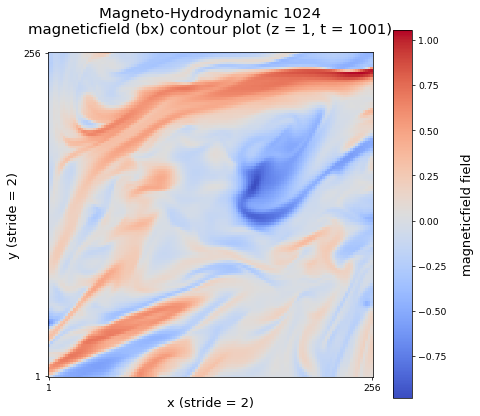

-----
contour plot created successfully.


In [8]:
"""
contour plot
"""
# b_1(x, y, 0, T) from the last downloaded variable (magneticfield), for comparison with the old wsindy_examples figure.
x_plot_range = [1, 256]
y_plot_range = [1, 256]
z_plot_range = [1, 1]
t_plot = 1001

plot_component = 0

output_filename = 'turbulence-plane_contour_plot'

"""
use the tools and contour plot gizmo.
"""
# combine all of the plot axis ranges together for simplicity.
plot_ranges = np.array([x_plot_range, y_plot_range, z_plot_range])

# create the contour plot.
contour_plot(dataset, plot_component, result, t_plot, plot_ranges, axes_ranges, strides, output_filename, colormap = 'coolwarm', equal_aspect_ratio = True)